# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Satellite Geomagnetic Risk Dataset](https://www.kaggle.com/datasets/muhammadahmeddata/satellite-geomagnetic-risk-and-anomalies-2027)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('global_satellite_geomagnetic_risk_2027.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Record_ID,Timestamp,Orbital_Sector,Solar_Cycle_Phase,Geomagnetic_Field_Strength_nT,Pole_Shift_Velocity_Km_Yr,Monthly_Satellite_Glitches,GPS_Signal_Deviation_Meters,Solar_Radiation_Flux_Index,Grid_Vulnerability_Score,Risk_Level_Target
0,1,2027-01-01 00:00:00,Antarctic High-Radiation Zone,Rising Activity Phase,47929.35,38.69,2,7.40,43.95,47.30,Moderate
1,2,2027-01-01 00:00:00,Pacific Telemetry Blackout Void,Quiet Baseline,40920.13,32.44,1,3.33,42.33,38.35,Moderate
2,3,2027-01-01 01:00:00,Antarctic High-Radiation Zone,Quiet Baseline,39876.64,33.17,4,1.67,85.14,67.33,Critical
3,4,2027-01-01 02:00:00,Pacific Telemetry Blackout Void,Quiet Baseline,41267.63,31.73,4,3.05,83.13,54.44,Moderate
4,5,2027-01-01 03:00:00,Arctic High-Latitude Auroral Oval,Solar Minimum Transition,26447.67,28.00,5,6.45,75.51,74.19,Critical


## last Five row

In [4]:
df.tail()

,Record_ID,Timestamp,Orbital_Sector,Solar_Cycle_Phase,Geomagnetic_Field_Strength_nT,Pole_Shift_Velocity_Km_Yr,Monthly_Satellite_Glitches,GPS_Signal_Deviation_Meters,Solar_Radiation_Flux_Index,Grid_Vulnerability_Score,Risk_Level_Target
14995,14996,2028-05-14 20:00:00,Pacific Telemetry Blackout Void,Quiet Baseline,47893.95,36.71,2,0.51,57.01,53.88,Moderate
14996,14997,2028-05-14 20:00:00,North Magnetic Pole Siberian Corridor,Solar Minimum Transition,40124.15,32.35,7,0.83,61.99,61.92,Moderate
14997,14998,2028-05-14 21:00:00,Equatorial Ionospheric Anomaly Belt,Solar Minimum Transition,49218.28,35.25,3,1.62,27.10,34.24,High
14998,14999,2028-05-14 22:00:00,Arctic High-Latitude Auroral Oval,Rising Activity Phase,23586.29,35.90,2,1.59,15.08,58.95,Moderate
14999,15000,2028-05-14 23:00:00,Equatorial Ionospheric Anomaly Belt,Geomagnetic Storm Peak,44444.34,45.00,6,0.73,57.35,66.20,Critical


## Shape of our dataset

In [5]:
df.shape

(15000, 11)

## List out all columns

In [6]:
df.columns

Index(['Record_ID', 'Timestamp', 'Orbital_Sector', 'Solar_Cycle_Phase',
       'Geomagnetic_Field_Strength_nT', 'Pole_Shift_Velocity_Km_Yr',
       'Monthly_Satellite_Glitches', 'GPS_Signal_Deviation_Meters',
       'Solar_Radiation_Flux_Index', 'Grid_Vulnerability_Score',
       'Risk_Level_Target'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Record_ID                          int64
Timestamp                         object
Orbital_Sector                    object
Solar_Cycle_Phase                 object
Geomagnetic_Field_Strength_nT    float64
Pole_Shift_Velocity_Km_Yr        float64
Monthly_Satellite_Glitches         int64
GPS_Signal_Deviation_Meters      float64
Solar_Radiation_Flux_Index       float64
Grid_Vulnerability_Score         float64
Risk_Level_Target                 object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Record_ID                      15000 non-null  int64  
 1   Timestamp                      15000 non-null  object 
 2   Orbital_Sector                 15000 non-null  object 
 3   Solar_Cycle_Phase              15000 non-null  object 
 4   Geomagnetic_Field_Strength_nT  15000 non-null  float64
 5   Pole_Shift_Velocity_Km_Yr      15000 non-null  float64
 6   Monthly_Satellite_Glitches     15000 non-null  int64  
 7   GPS_Signal_Deviation_Meters    15000 non-null  float64
 8   Solar_Radiation_Flux_Index     15000 non-null  float64
 9   Grid_Vulnerability_Score       15000 non-null  float64
 10  Risk_Level_Target              15000 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.3+ MB


## Check Null Value

In [9]:
df.isnull().sum()

Record_ID                        0
Timestamp                        0
Orbital_Sector                   0
Solar_Cycle_Phase                0
Geomagnetic_Field_Strength_nT    0
Pole_Shift_Velocity_Km_Yr        0
Monthly_Satellite_Glitches       0
GPS_Signal_Deviation_Meters      0
Solar_Radiation_Flux_Index       0
Grid_Vulnerability_Score         0
Risk_Level_Target                0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,Record_ID,Geomagnetic_Field_Strength_nT,Pole_Shift_Velocity_Km_Yr,Monthly_Satellite_Glitches,GPS_Signal_Deviation_Meters,Solar_Radiation_Flux_Index,Grid_Vulnerability_Score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,37558.242875,34.835705,4.230600,4.261673,52.400205,55.232802
std,4330.271354,9799.029037,3.139765,2.064035,4.843769,21.712215,11.405626
min,1.000000,21001.270000,28.000000,0.000000,0.000000,15.000000,21.420000
25%,3750.750000,27873.070000,32.630000,3.000000,1.090000,33.760000,47.050000
50%,7500.500000,40239.185000,34.840000,4.000000,2.705000,52.440000,55.020000
75%,11250.250000,46195.012500,36.950000,6.000000,5.630000,71.192500,63.100000
max,15000.000000,51999.550000,45.000000,13.000000,50.990000,90.000000,97.290000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

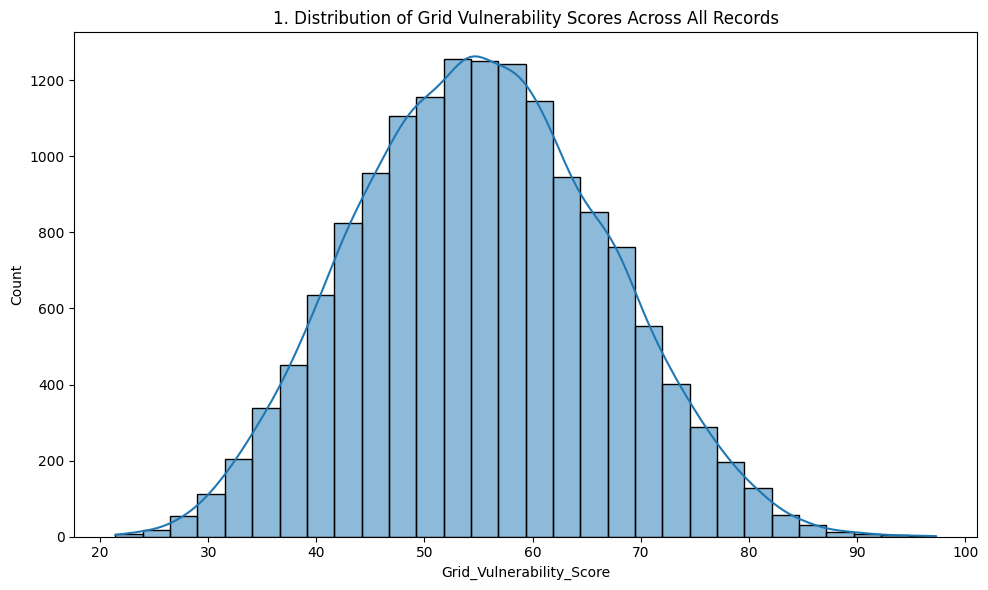

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Grid_Vulnerability_Score', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Grid Vulnerability Scores Across All Records')
show_fig()
plot_no += 1

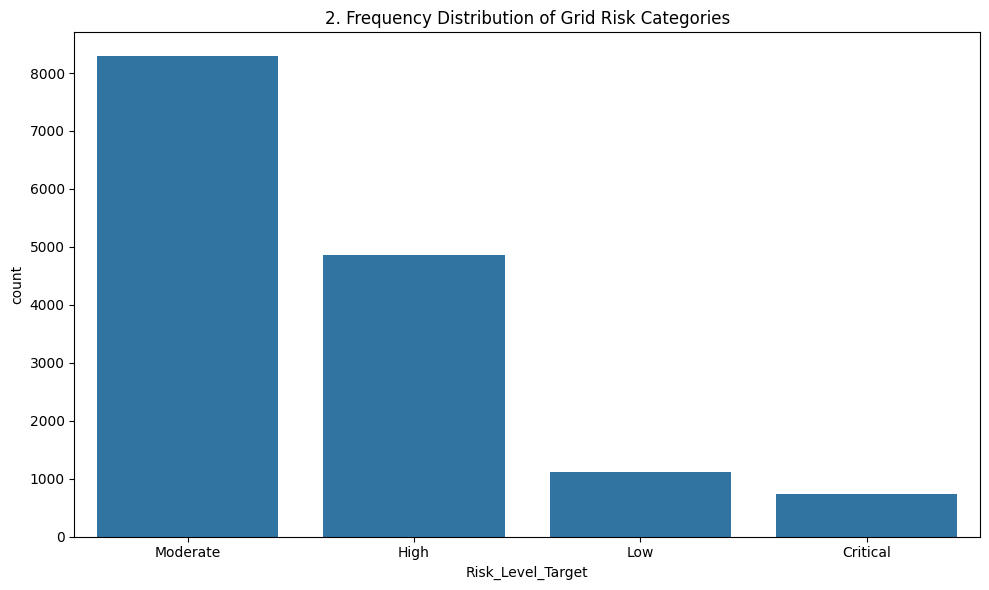

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Risk_Level_Target', order=df['Risk_Level_Target'].value_counts().index)
plt.title(f'{plot_no}. Frequency Distribution of Grid Risk Categories')
show_fig()
plot_no += 1

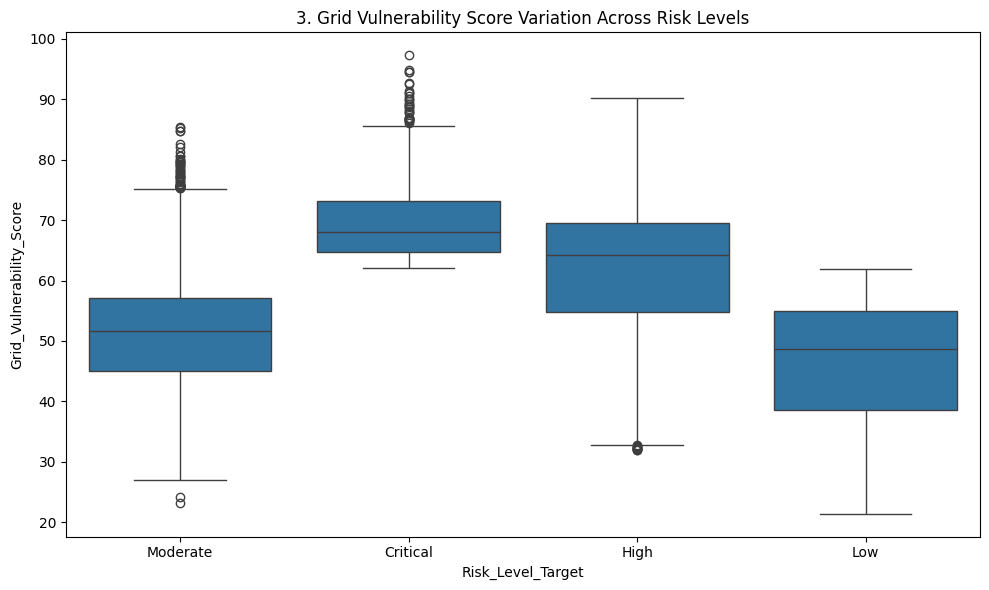

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Risk_Level_Target', y='Grid_Vulnerability_Score')
plt.title(f'{plot_no}. Grid Vulnerability Score Variation Across Risk Levels')
show_fig()
plot_no += 1

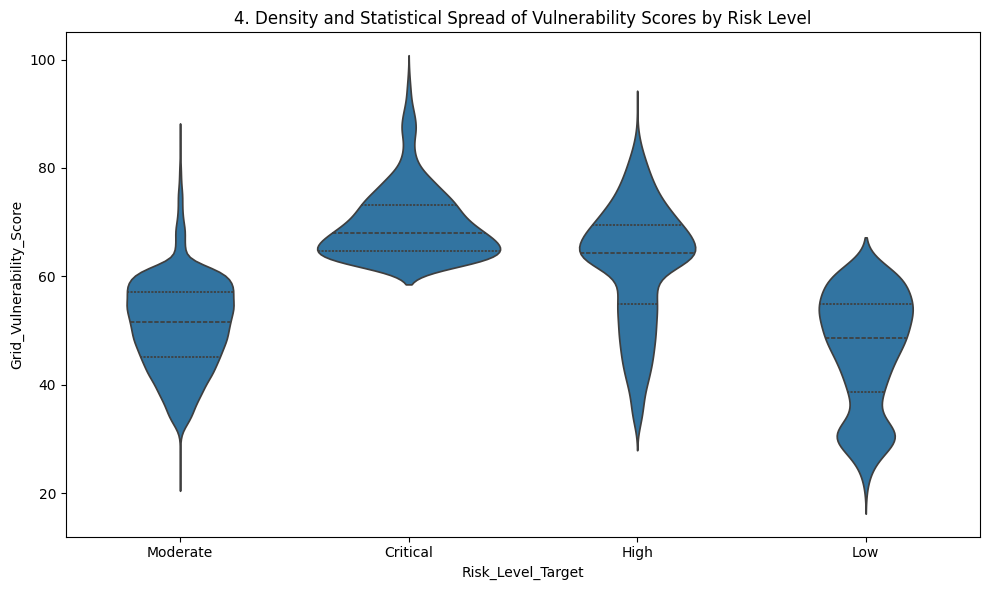

In [16]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Risk_Level_Target', y='Grid_Vulnerability_Score', inner='quartile')
plt.title(f'{plot_no}. Density and Statistical Spread of Vulnerability Scores by Risk Level')
show_fig()
plot_no += 1

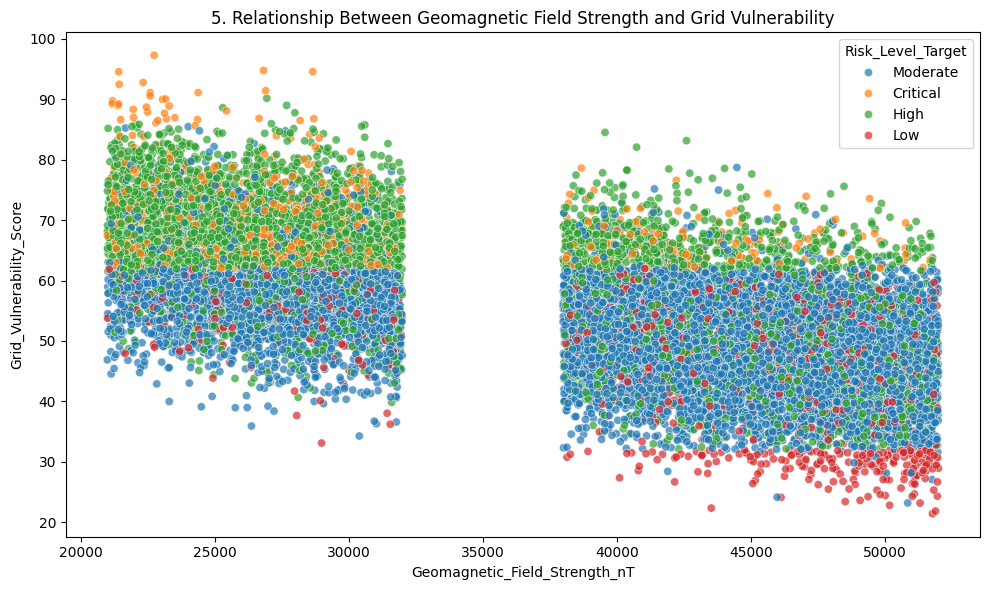

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Geomagnetic_Field_Strength_nT', y='Grid_Vulnerability_Score', hue='Risk_Level_Target', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Geomagnetic Field Strength and Grid Vulnerability')
show_fig()
plot_no += 1

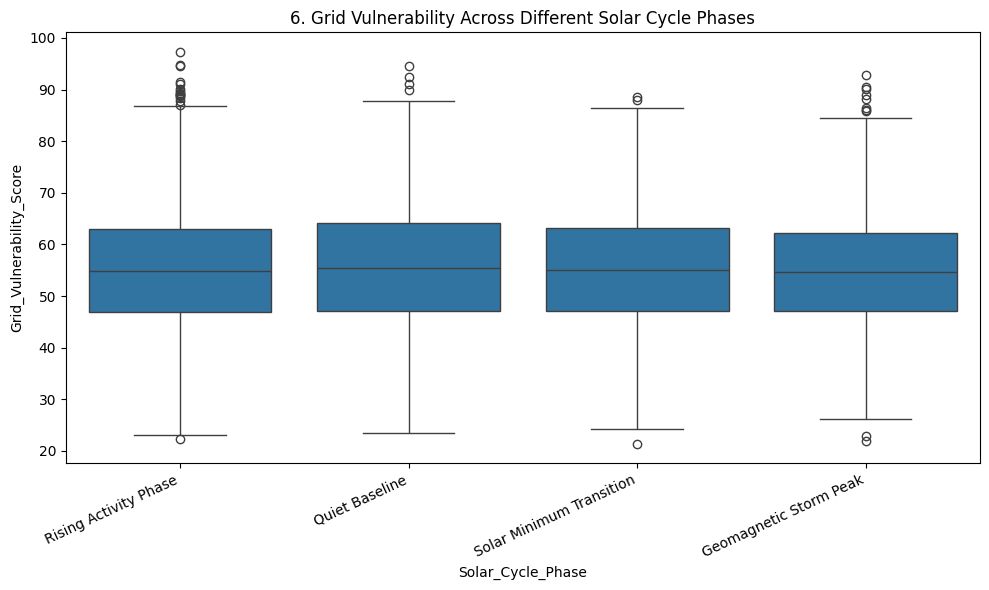

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Solar_Cycle_Phase', y='Grid_Vulnerability_Score')
plt.xticks(rotation=25, ha='right')
plt.title(f'{plot_no}. Grid Vulnerability Across Different Solar Cycle Phases')
show_fig()
plot_no += 1

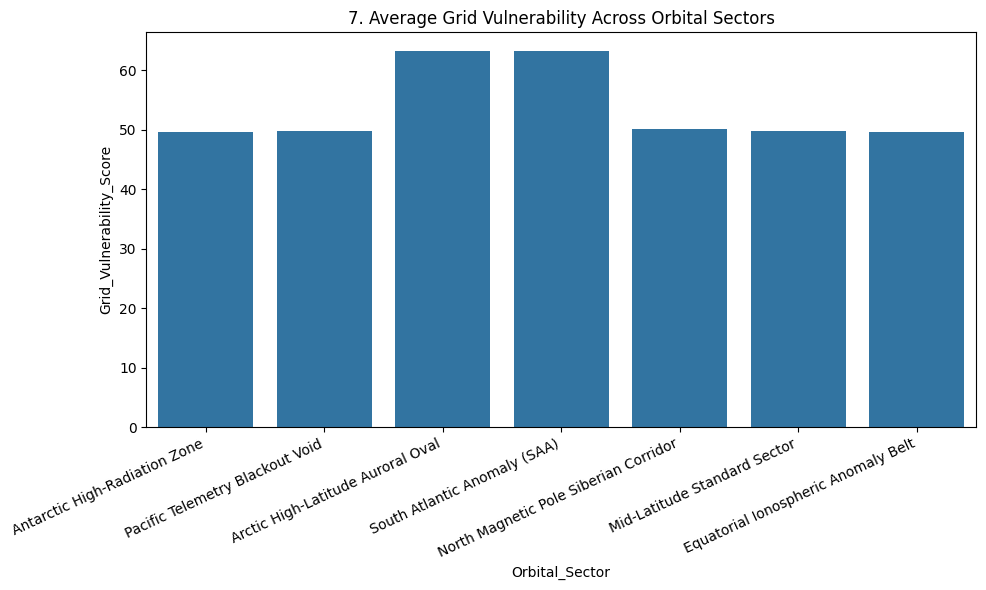

In [19]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Orbital_Sector', y='Grid_Vulnerability_Score', estimator='mean', errorbar=None)
plt.xticks(rotation=25, ha='right')
plt.title(f'{plot_no}. Average Grid Vulnerability Across Orbital Sectors')
show_fig()
plot_no += 1

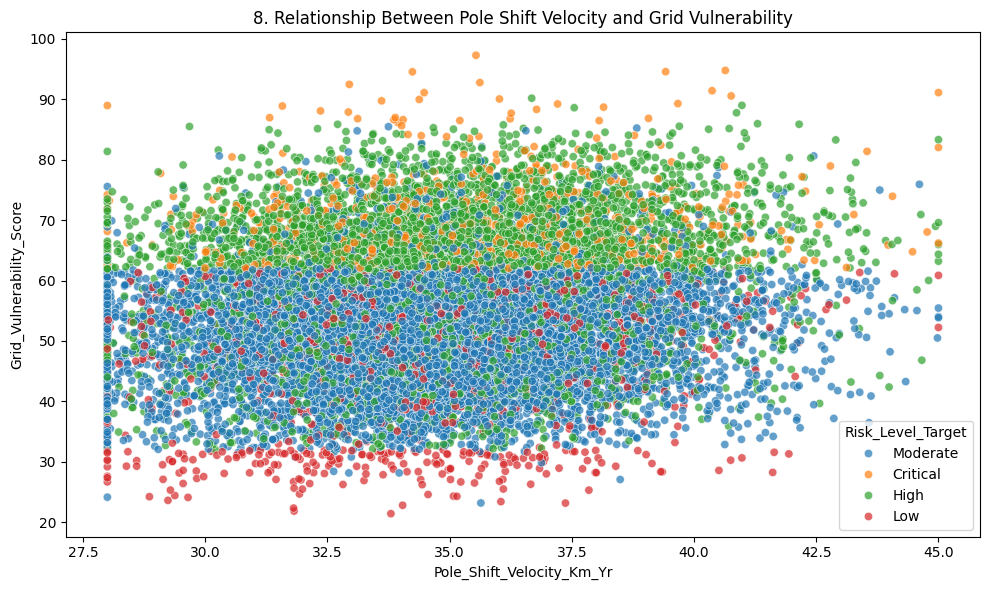

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Pole_Shift_Velocity_Km_Yr', y='Grid_Vulnerability_Score', hue='Risk_Level_Target', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Pole Shift Velocity and Grid Vulnerability')
show_fig()
plot_no += 1

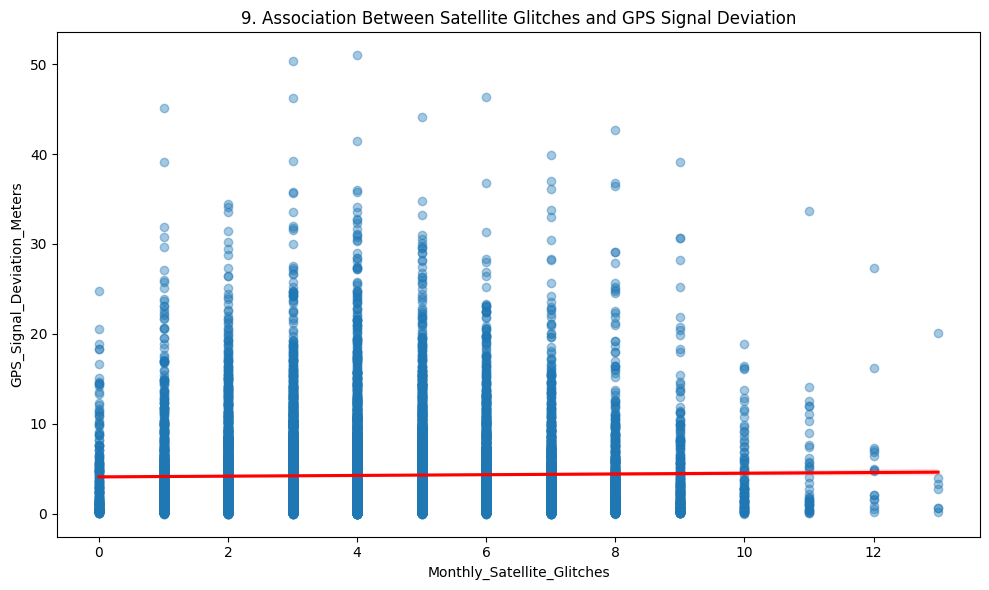

In [21]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Monthly_Satellite_Glitches', y='GPS_Signal_Deviation_Meters', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Satellite Glitches and GPS Signal Deviation')
show_fig()
plot_no += 1

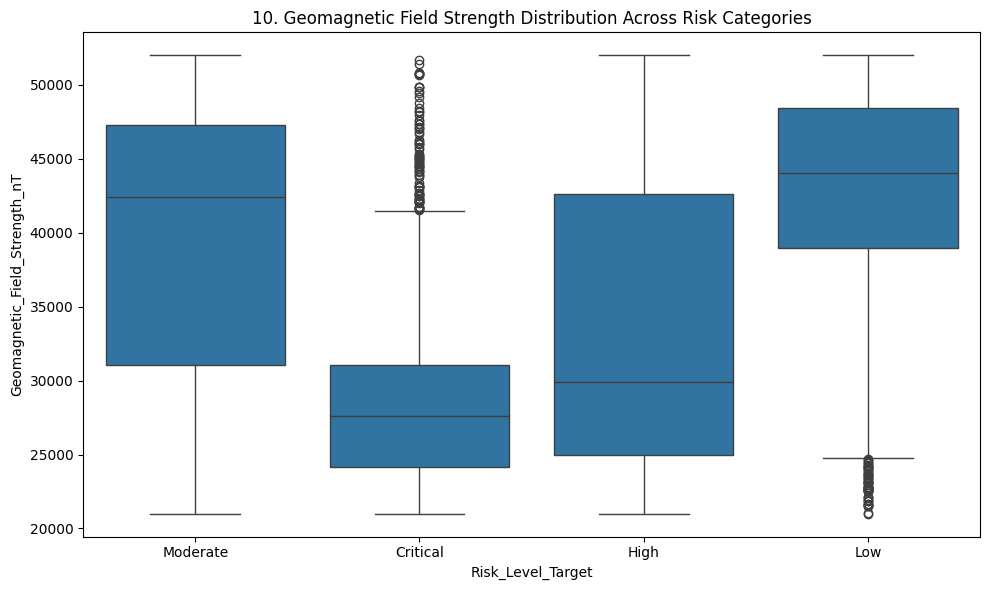

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Risk_Level_Target', y='Geomagnetic_Field_Strength_nT')
plt.title(f'{plot_no}. Geomagnetic Field Strength Distribution Across Risk Categories')
show_fig()
plot_no += 1

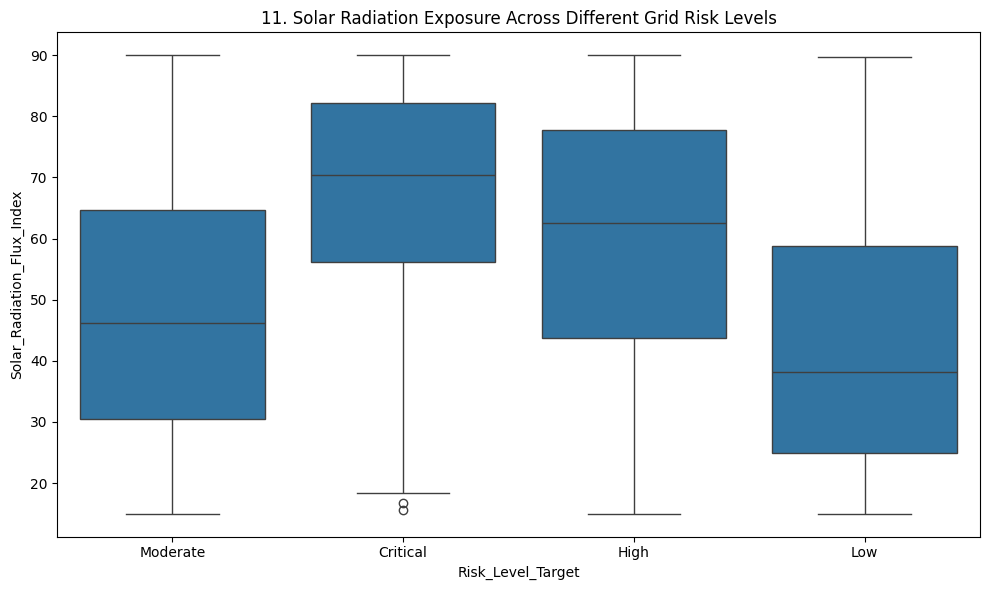

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Risk_Level_Target', y='Solar_Radiation_Flux_Index')
plt.title(f'{plot_no}. Solar Radiation Exposure Across Different Grid Risk Levels')
show_fig()
plot_no += 1

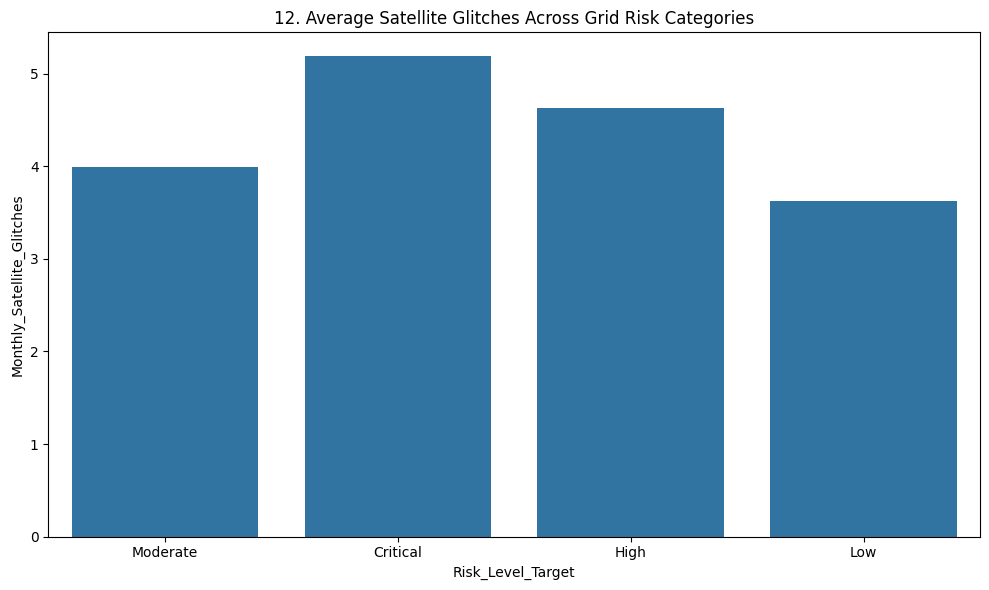

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Risk_Level_Target', y='Monthly_Satellite_Glitches', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Satellite Glitches Across Grid Risk Categories')
show_fig()
plot_no += 1

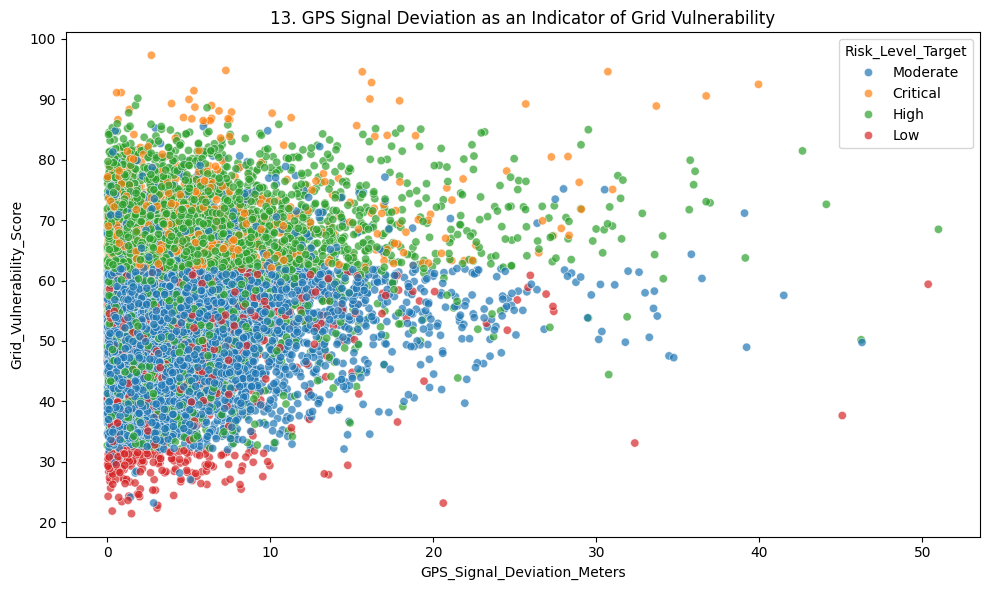

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='GPS_Signal_Deviation_Meters', y='Grid_Vulnerability_Score', hue='Risk_Level_Target', alpha=0.7)
plt.title(f'{plot_no}. GPS Signal Deviation as an Indicator of Grid Vulnerability')
show_fig()
plot_no += 1

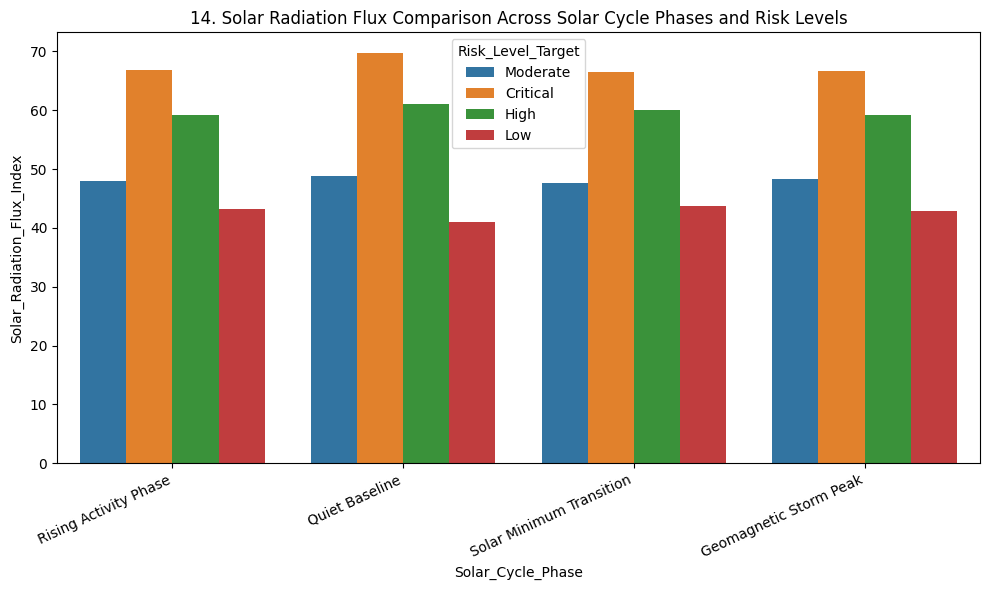

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Solar_Cycle_Phase', y='Solar_Radiation_Flux_Index', hue='Risk_Level_Target', errorbar=None)
plt.xticks(rotation=25, ha='right')
plt.title(f'{plot_no}. Solar Radiation Flux Comparison Across Solar Cycle Phases and Risk Levels')
show_fig()
plot_no += 1

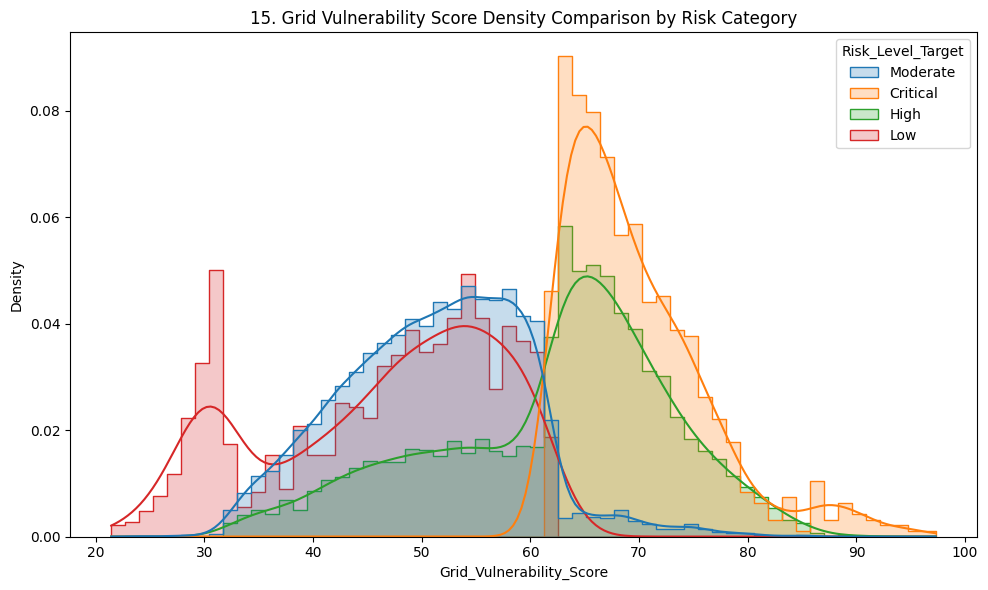

In [27]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Grid_Vulnerability_Score', hue='Risk_Level_Target', kde=True, element='step', stat='density', common_norm=False)
plt.title(f'{plot_no}. Grid Vulnerability Score Density Comparison by Risk Category')
show_fig()
plot_no += 1

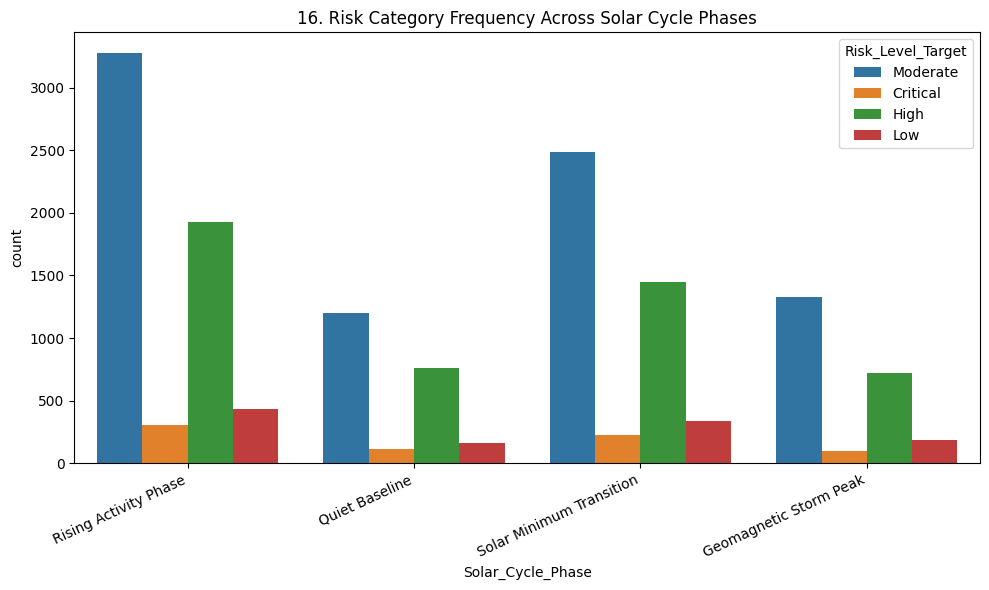

In [28]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Solar_Cycle_Phase', hue='Risk_Level_Target')
plt.xticks(rotation=25, ha='right')
plt.title(f'{plot_no}. Risk Category Frequency Across Solar Cycle Phases')
show_fig()
plot_no += 1

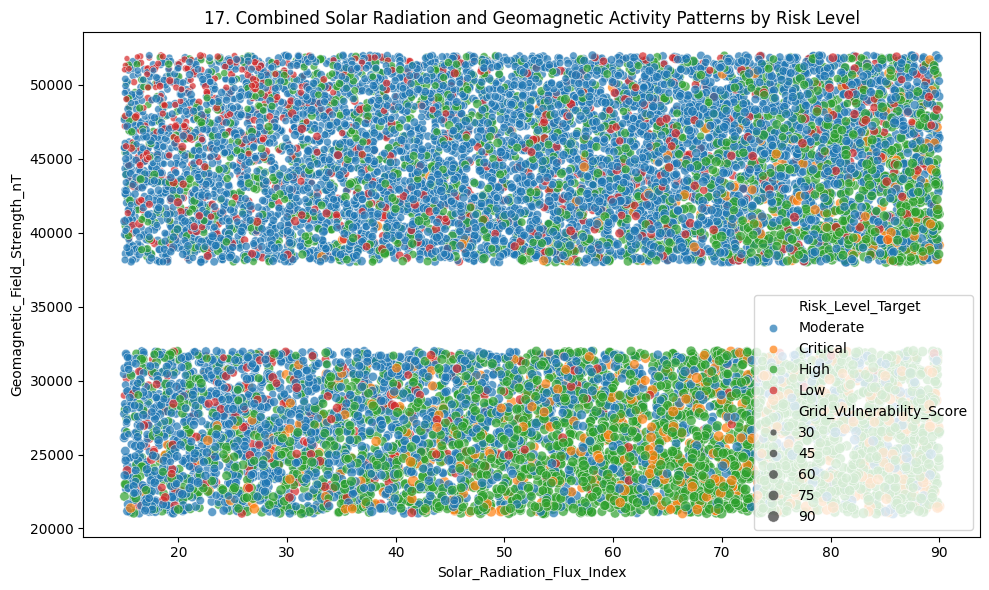

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Solar_Radiation_Flux_Index', y='Geomagnetic_Field_Strength_nT', hue='Risk_Level_Target', size='Grid_Vulnerability_Score', alpha=0.7)
plt.title(f'{plot_no}. Combined Solar Radiation and Geomagnetic Activity Patterns by Risk Level')
show_fig()
plot_no += 1

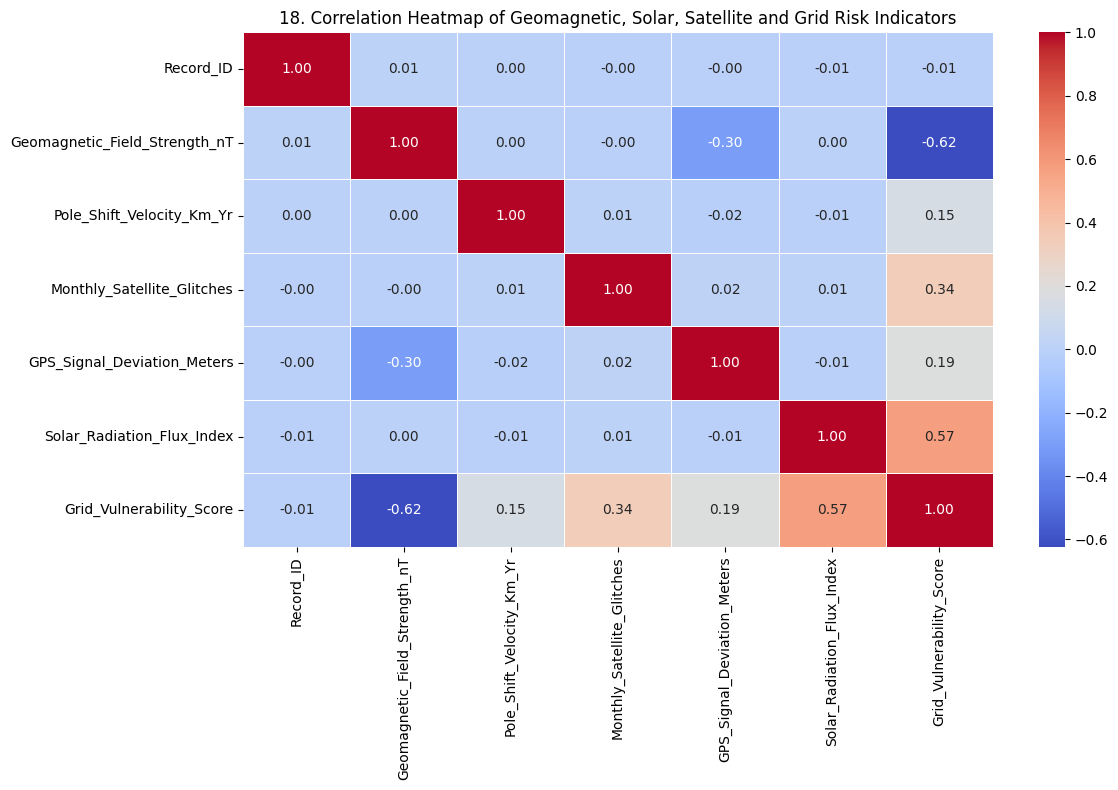

In [30]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Geomagnetic, Solar, Satellite and Grid Risk Indicators')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [31]:
X = df.drop(columns=['Grid_Vulnerability_Score', 'Record_ID', 'Timestamp'])
y = df['Grid_Vulnerability_Score']

## Identify numerical and categorical columns

In [32]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Preprocess missing values and categorical features

In [33]:
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

## Split dataset into training and testing sets

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create Gradient Boosting regression model

In [35]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.85,
        random_state=42
    ))
])

## Train the model

In [36]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [37]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [38]:
print("R2 Score:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

R2 Score: 0.8599
MAE: 3.3955
RMSE: 4.2612


## Plot actual vs predicted values

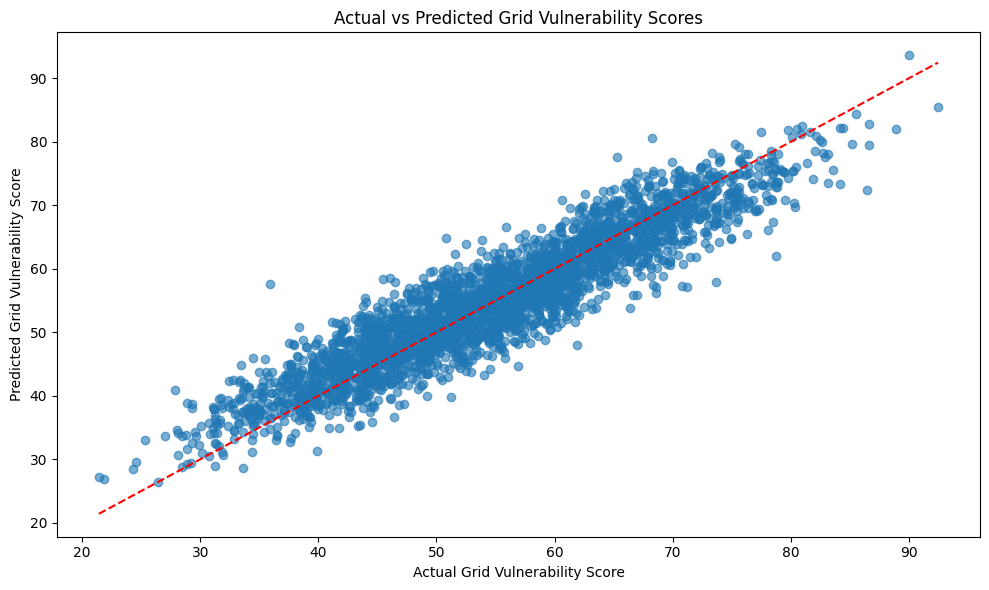

In [39]:
fig = plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual Grid Vulnerability Score')
plt.ylabel('Predicted Grid Vulnerability Score')
plt.title('Actual vs Predicted Grid Vulnerability Scores')
show_fig()